# 04 — Disease Area

**Dataset:** `data/processed/trials.parquet` (labels), `data/processed/eligibility_features.parquet` (strictness
score from 03), and the AACT condition tables `data/raw/browse_conditions.parquet` and `data/raw/conditions.parquet`.

**Why this notebook exists.** Notebook 03 found that stricter eligibility criteria go with more enrollment failure
(OR 1.14 per extra restriction type, after adjusting for phase, sponsor, healthy volunteers, and year). But the rules
most linked to failure (performance status, prior therapy, brain metastases) are typical of **cancer trials**, and
cancer trials may be harder to recruit for whatever their criteria say. If so, disease area is a **confounder**: it
drives both strictness and failure, and could create part of the strictness effect.

**Questions this notebook answers**
1. How do we assign each trial to a disease area using the information AACT provides?
2. How much does the enrollment failure rate vary across disease areas?
3. Do some disease areas write stricter criteria than others? (Needed for confounding.)
4. Within a single disease area, does failure still rise with strictness?
5. After adding disease area to the 03 regression, how much of the strictness effect remains?

**Output:** `data/processed/disease_area.parquet`, with one row per trial (all 231,776, not just labeled trials),
for the full model (09) and the representation work (06/08).

> Disease area comes from the conditions a sponsor registers when the trial starts, so it is known before launch and
> is not leakage. One caveat: the mapping to MeSH terms is redone by NLM on the current record, so a condition edited
> after launch would show its edited version.

## 1. Setup

Load the labeled trials and attach Neha's strictness features from 03. `BASE` is the overall failure rate, used as a
reference line in the plots. `wilson()` gives a 95% confidence interval for a rate, which keeps small groups from
looking more certain than they are.

In [1]:
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")          # silence convergence chatter from the small per-area models
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(FIG / f"disease_{name}.png", bbox_inches="tight", dpi=200)

def wilson(k, n, z=1.96):
    # 95% confidence interval for a proportion k/n
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def rates(df, col):
    # failure rate (with 95% CI) for each value of `col`
    t = df.groupby(col, observed=True)["label"].agg(n="size", k="sum")
    t["rate"] = t["k"] / t["n"]
    t["lo"], t["hi"] = wilson(t["k"], t["n"])
    return t

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet",
                         columns=["nct_id", "label", "phase", "lead_sponsor_class",
                                  "healthy_volunteers", "start_year"])
elig = pd.read_parquet(ROOT / "data/processed/eligibility_features.parquet")
mesh = pd.read_parquet(ROOT / "data/raw/browse_conditions.parquet",
                       columns=["nct_id", "mesh_term", "downcase_mesh_term", "mesh_type"])
conds = pd.read_parquet(ROOT / "data/raw/conditions.parquet", columns=["nct_id", "name", "downcase_name"])

BASE = trials["label"].mean()
print(f"{len(trials):,} trials in cohort, {trials['label'].notna().sum():,} labeled, base failure rate {BASE:.2%}")

231,776 trials in cohort, 164,593 labeled, base failure rate 4.79%


## 2. How AACT describes a trial's disease

There are two tables:

| Table | What it holds | Example |
|---|---|---|
| `conditions` | Free text typed by the sponsor | "Breast Cancer", "Peripheral Neuropathies" |
| `browse_conditions` | Those conditions mapped by NLM to **MeSH**, the controlled medical vocabulary used by PubMed | "Breast Neoplasms" |

MeSH is a tree. "Breast Neoplasms" sits under "Neoplasms by Site", which sits under "Neoplasms". `browse_conditions`
stores both levels:
- **`mesh-list`**: the specific terms matched to the trial's conditions.
- **`mesh-ancestor`**: every parent of those terms, up to the top of the tree.

The top of the tree is a short list of broad categories (Neoplasms, Cardiovascular Diseases, Infections, …). These
categories become our disease areas. Here is one trial:

In [2]:
ex = "NCT03449303"
print("Sponsor typed:", conds.loc[conds["nct_id"] == ex, "name"].tolist())
mesh.loc[mesh["nct_id"] == ex, ["mesh_type", "mesh_term"]].sort_values("mesh_type", ascending=False)

Sponsor typed: ['Breast Cancer', 'Peripheral Neuropathies']


,mesh_type,mesh_term
409313,mesh-list,Breast Neoplasms
409314,mesh-list,Peripheral Nervous System Diseases
409315,mesh-list,Pain
409290,mesh-ancestor,Neoplasms by Site
409291,mesh-ancestor,Neoplasms
409305,mesh-ancestor,Breast Diseases
409306,mesh-ancestor,Skin Diseases
409307,mesh-ancestor,Skin and Connective Tissue Diseases
409308,mesh-ancestor,Neuromuscular Diseases
409309,mesh-ancestor,Nervous System Diseases


Two things to notice:
- One trial can fall into **several** broad categories. This one is a cancer trial, a nervous-system trial, and a
  "signs and symptoms" (pain) trial.
- MeSH has quirks. **Breast diseases are filed under Skin and Connective Tissue Diseases**, so every breast cancer
  trial is also a "skin" trial. Step 5 has to deal with this.

## 3. Map MeSH categories to disease areas

Each disease area is defined by one or more top-level MeSH categories. A trial is flagged for an area if **any** of
its MeSH terms (`mesh-list` or `mesh-ancestor`) is one of that area's categories. Both row types are searched
because a trial whose own term is already top level (say, just "Neoplasms") has no ancestor row for it.

Choices worth knowing:
- `metabolic_endocrine` merges two MeSH branches, because diabetes sits in both.
- `behavioral` catches lifestyle trials (smoking cessation, exercise, medication adherence). Their MeSH terms
  are not in the disease branches at all.
- `symptoms_other` is MeSH's catch-all for signs and symptoms (pain, fatigue, nausea, …). It is attached to many
  trials, so it ranks last when choosing a primary area (Step 5).

In [3]:
# area name -> top-level MeSH categories that define it (lower-case, as in downcase_mesh_term)
AREAS = {
    "oncology":               ["neoplasms"],
    "infectious":             ["infections", "bacterial infections and mycoses", "virus diseases", "parasitic diseases"],
    "mental_health":          ["mental disorders"],
    "renal_urologic":         ["urologic diseases"],
    "cardiovascular":         ["cardiovascular diseases"],
    "metabolic_endocrine":    ["nutritional and metabolic diseases", "endocrine system diseases"],
    "respiratory":            ["respiratory tract diseases"],
    "digestive":              ["digestive system diseases"],
    "reproductive_pregnancy": ["female urogenital diseases and pregnancy complications", "genital diseases",
                               "pregnancy complications"],
    "musculoskeletal":        ["musculoskeletal diseases"],
    "skin_connective":        ["skin and connective tissue diseases"],
    "eye_ent_oral":           ["eye diseases", "otorhinolaryngologic diseases", "stomatognathic diseases"],
    "neurology":              ["nervous system diseases"],
    "blood":                  ["hemic and lymphatic diseases"],
    "immune":                 ["immune system diseases"],
    "injury":                 ["wounds and injuries"],
    "congenital":             ["congenital, hereditary, and neonatal diseases and abnormalities"],
    "behavioral":             ["behavior"],
    "symptoms_other":         ["pathological conditions, signs and symptoms", "chemically-induced disorders",
                               "occupational diseases", "disorders of environmental origin"],
}
term_to_area = {term: area for area, terms in AREAS.items() for term in terms}

# One row per trial, one True/False column per area
mesh["area"] = mesh["downcase_mesh_term"].map(term_to_area)
flags = (pd.crosstab(mesh["nct_id"], mesh["area"]) > 0)
flags = flags.reindex(index=trials["nct_id"], columns=list(AREAS), fill_value=False)

has_mesh = trials["nct_id"].isin(mesh["nct_id"]).to_numpy()
has_area = flags.any(axis=1).to_numpy()
print(f"Trials with any MeSH term:          {has_mesh.mean():.1%}")
print(f"Trials mapped to at least one area: {has_area.mean():.1%}")
(flags.mean() * 100).sort_values(ascending=False).round(1).to_frame("% of trials flagged")

Trials with any MeSH term:          79.2%
Trials mapped to at least one area: 79.0%


,% of trials flagged
area,
symptoms_other,24.7
oncology,17.6
neurology,11.6
metabolic_endocrine,11.4
cardiovascular,9.7
reproductive_pregnancy,8.6
respiratory,8.3
mental_health,7.9
immune,7.8


## 4. Fill the gaps: trials with no MeSH area

About a fifth of trials end up with no area. Some are missed by NLM's mapping even though the condition is obvious
("hiv", "solid tumors", "plaque psoriasis"). Many are **healthy-volunteer studies** (condition = "Healthy"), such as
phase 1 drug-metabolism or bioequivalence studies.

For these trials only, the sponsor's free-text condition is searched with a few keyword patterns. Trials that match
no disease keyword but list "healthy" as a condition get their own area, `healthy`. The rest stay `unclassified`
(anesthesia, surgery, and pharmacokinetics studies, for example).

`area_source` records how each trial got its area, so the model can tell a MeSH-based area from a keyword guess.

In [4]:
# Keyword fallback, applied only to trials that MeSH left without an area
KEYWORDS = {
    "oncology":            r"cancer|tumou?r|carcinoma|leuka?emia|lymphoma|myeloma|neoplas|sarcoma|melanoma|glioma|metasta|malignan",
    "infectious":          r"\bhiv\b|hiv-1|hepatitis|covid|sars-cov|influenza|malaria|tubercul|infection|vaccin",
    "cardiovascular":      r"hypertension|blood pressure|heart|cardiac|coronary|atrial fib|stroke",
    "metabolic_endocrine": r"diabet|obes|overweight",
    "skin_connective":     r"psoria|dermatitis|eczema|acne",
    "eye_ent_oral":        r"macula|retin|glaucoma|cataract|myopia|visual acuity|dry eye|dental|periodont|teeth|tooth",
}
HEALTHY = r"^healthy|healthy (?:volunteer|subject|participant|adult|individual|women|men)|^normal (?:volunteer|subject)"

missing = flags.index[~has_area]
text = conds.groupby("nct_id")["downcase_name"].agg(" | ".join).reindex(missing).fillna("")
for area, pattern in KEYWORDS.items():
    hit = text.index[text.str.contains(pattern, regex=True)]
    flags.loc[hit, area] = True

still_missing = ~flags.loc[missing].any(axis=1)
flags["healthy"] = False
flags.loc[text.index[still_missing & text.str.contains(HEALTHY, regex=True)], "healthy"] = True

source = pd.Series("none", index=flags.index)
source[has_area] = "mesh"
source[~has_area & flags.drop(columns="healthy").any(axis=1)] = "keyword"
source[flags["healthy"]] = "healthy"
source.value_counts().to_frame("trials")

,trials
mesh,182994
none,30735
keyword,10674
healthy,7373


## 5. One primary area per trial

The True/False flags from Step 3 are the main **model features**: XGBoost in 09 can use all of them, and a trial in
both oncology and neurology simply has both set. But a stratified analysis ("strictness *within* oncology") needs
each trial in exactly one group. So each trial also gets a **primary area**: the first area in the priority list
below that the trial is flagged for.

How the order was chosen: **specific, recruitment-defining areas come first, and broad catch-alls come last.**
- **Oncology first.** Cancer trials have distinctive criteria and recruitment, and 70% of blood-disease trials
  are cancers (leukemia, lymphoma). This also stops breast cancer from landing in "skin".
- **Infectious before immune**, so HIV (which MeSH also files under immune deficiency) counts as infectious.
- **Renal before cardiovascular and metabolic**, so diabetic kidney disease counts as renal
- **Neurology late**, because MeSH puts "pain" under nervous-system diseases. With neurology early, every pain
  trial would become neurology.
- A known side effect: **stroke** is filed under both cardiovascular and nervous system, so it lands in
  cardiovascular.

Any order is a judgment call. Step 8 checks whether it matters by also fitting the model with all the flags instead
of the primary area.

In [5]:
PRIORITY = list(AREAS) + ["healthy"]     # the AREAS dict above is already written in priority order
primary = pd.Series(np.select([flags[a] for a in PRIORITY], PRIORITY, default="unclassified"),
                    index=flags.index, name="primary_area")
n_areas = flags[list(AREAS)].sum(axis=1).rename("n_areas")

print("Number of areas per trial (MeSH-mapped trials):")
print(n_areas[has_area].value_counts().sort_index().head(6).to_string())
print(f"{(n_areas[has_area] > 1).mean():.0%} of mapped trials fall in more than one area\n")

# Example: the breast-cancer + neuropathy trial from Step 2
print(ex, "->", flags.columns[flags.loc[ex]].tolist(), "-> primary:", primary[ex])

Number of areas per trial (MeSH-mapped trials):
n_areas
1    65504
2    68575
3    33906
4    10756
5     2812
6      874
64% of mapped trials fall in more than one area

NCT03449303 -> ['oncology', 'skin_connective', 'neurology', 'symptoms_other'] -> primary: oncology


## 6. How much does failure vary by disease area?

Failure rate (terminated for low enrollment) by primary area, on labeled trials only. The bars show 95% confidence
intervals, and the dashed line is the overall rate.

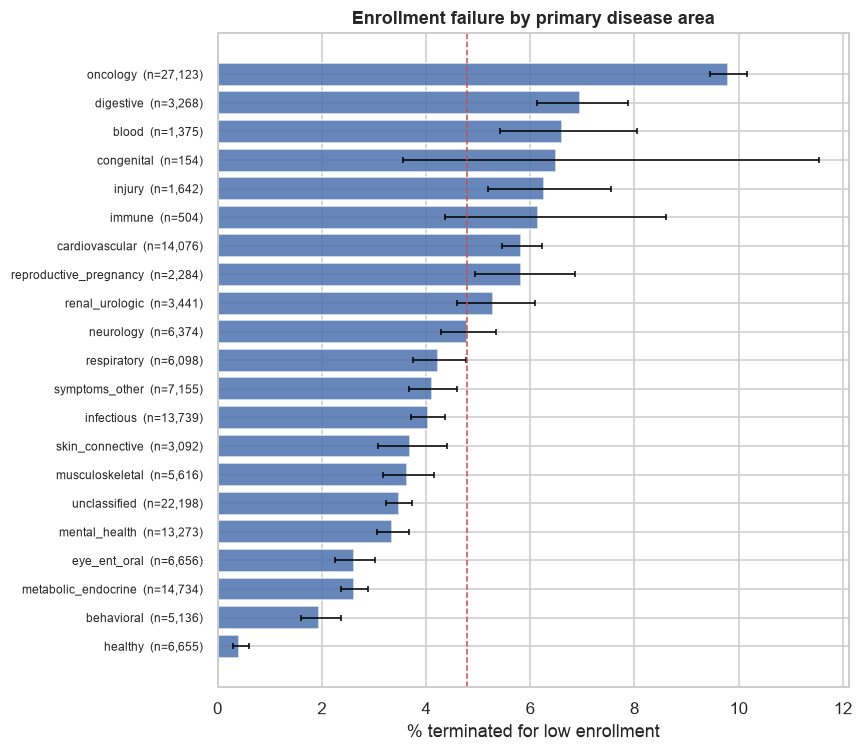

,n,k,rate,lo,hi
primary_area,,,,,
oncology,27123,2656.0,9.79,9.44,10.15
digestive,3268,227.0,6.95,6.12,7.87
blood,1375,91.0,6.62,5.42,8.06
congenital,154,10.0,6.49,3.57,11.54
injury,1642,103.0,6.27,5.20,7.55
immune,504,31.0,6.15,4.37,8.60
cardiovascular,14076,821.0,5.83,5.46,6.23
reproductive_pregnancy,2284,133.0,5.82,4.93,6.86
renal_urologic,3441,182.0,5.29,4.59,6.09


In [6]:
area_df = pd.concat([primary, n_areas, source.rename("area_source")], axis=1).reset_index()
labeled = (trials[trials["label"].notna()]
           .merge(area_df, on="nct_id")
           .merge(elig, on="nct_id"))
LBASE = labeled["label"].mean()

by_area = rates(labeled, "primary_area").sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(by_area))
ax.barh(y, by_area["rate"] * 100, color="#4C72B0", alpha=0.85)
ax.errorbar(by_area["rate"] * 100, y,
            xerr=[(by_area["rate"] - by_area["lo"]) * 100, (by_area["hi"] - by_area["rate"]) * 100],
            fmt="none", ecolor="black", lw=1, capsize=2)
ax.axvline(LBASE * 100, ls="--", color="#C44E52", lw=1)
ax.set_yticks(y, [f"{a}  (n={n:,})" for a, n in zip(by_area.index, by_area["n"])], fontsize=8)
ax.set_xlabel("% terminated for low enrollment")
ax.set_title("Enrollment failure by primary disease area")
plt.tight_layout(); savefig("failure_by_area"); plt.show()

(by_area.assign(rate=lambda t: t["rate"] * 100, lo=lambda t: t["lo"] * 100, hi=lambda t: t["hi"] * 100)
        .sort_values("rate", ascending=False).round(2))

## 7. Is disease area a confounder?

For disease area to distort the strictness result, two things must both be true:
1. Disease area is linked to **failure**. Step 6 showed this.
2. Disease area is linked to **strictness**: some areas write many more restriction types than others.

Each dot below is one disease area. If the dots run from bottom-left to top-right, the areas that write strict
criteria are also the areas that fail more often. Comparing *across* areas like this would then make strictness
look harmful even if it had no effect *inside* any single area.

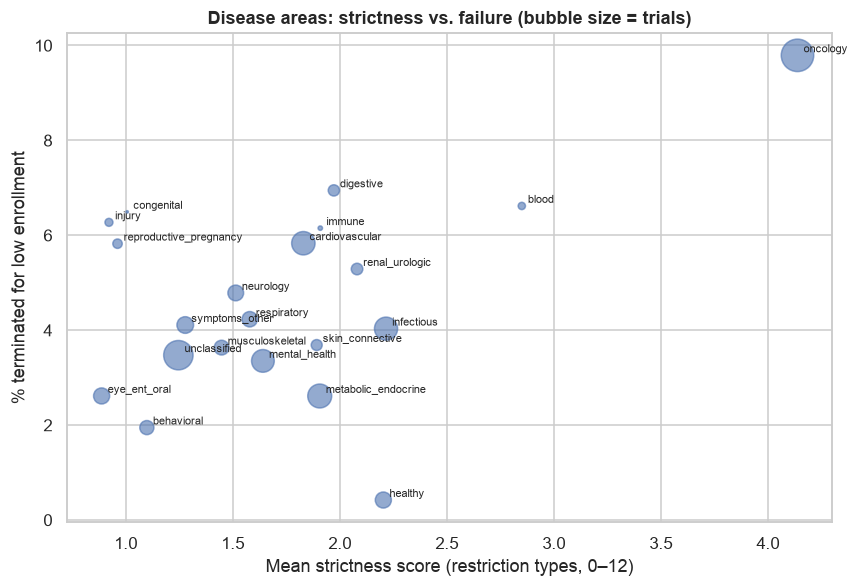

Across areas, Spearman correlation between mean strictness and failure rate: 0.22 (p = 0.328)


,n,rate,strictness
primary_area,,,
oncology,27123,0.098,4.138
blood,1375,0.066,2.850
infectious,13739,0.040,2.216
healthy,6655,0.004,2.203
renal_urologic,3441,0.053,2.080
digestive,3268,0.069,1.972
immune,504,0.062,1.909
metabolic_endocrine,14734,0.026,1.906
skin_connective,3092,0.037,1.892


In [7]:
per_area = labeled.groupby("primary_area").agg(n=("label", "size"), rate=("label", "mean"),
                                               strictness=("n_rule_types", "mean"))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(per_area["strictness"], per_area["rate"] * 100, s=per_area["n"] / 60, alpha=0.6, color="#4C72B0")
for a, r in per_area.iterrows():
    ax.annotate(a, (r["strictness"], r["rate"] * 100), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("Mean strictness score (restriction types, 0–12)")
ax.set_ylabel("% terminated for low enrollment")
ax.set_title("Disease areas: strictness vs. failure (bubble size = trials)")
plt.tight_layout(); savefig("strictness_vs_failure"); plt.show()

r, p = stats.spearmanr(per_area["strictness"], per_area["rate"])
print(f"Across areas, Spearman correlation between mean strictness and failure rate: {r:.2f} (p = {p:.3f})")
per_area.sort_values("strictness", ascending=False).round(3)

## 8. Does strictness still matter *within* each disease area?

This is the main test. If strictness only looked harmful because cancer trials are both strict and hard to recruit,
the failure gradient should **flatten** once we look inside one area at a time.

**8a. Picture:** failure rate by strictness score within each of the 12 largest areas. Scores of 6 and above are
pooled, and points with fewer than 50 trials are hidden.

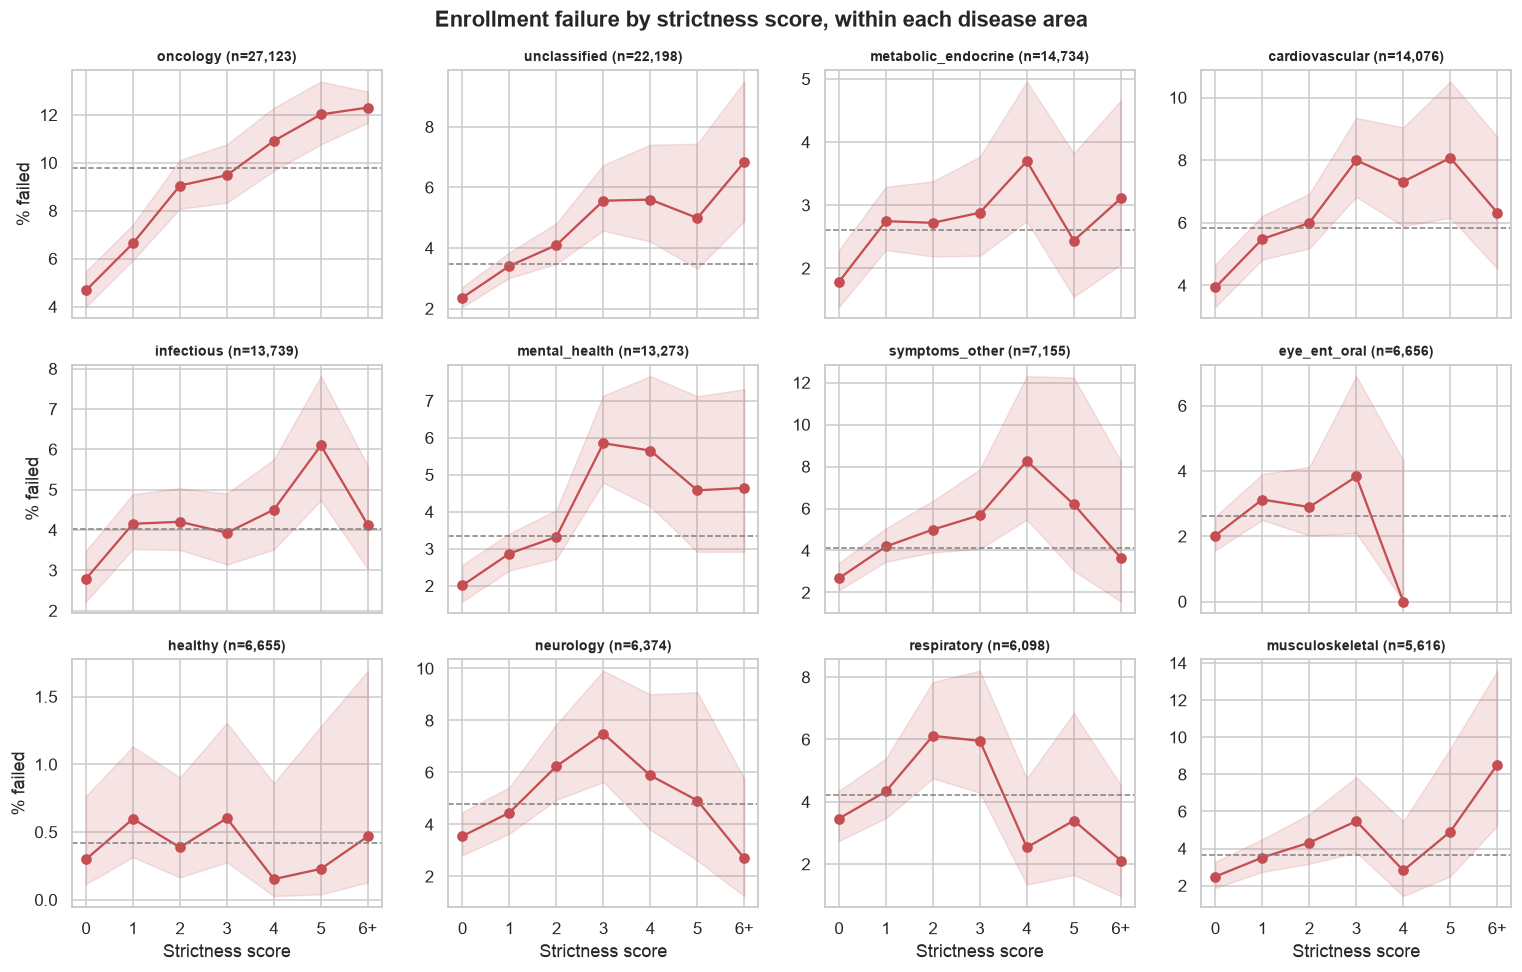

In [8]:
labeled["strict_bin"] = labeled["n_rule_types"].clip(upper=6)
top_areas = labeled["primary_area"].value_counts().index[:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 9), sharex=True)
for ax, area in zip(axes.flat, top_areas):
    g = rates(labeled[labeled["primary_area"] == area], "strict_bin")
    g = g[g["n"] >= 50]
    ax.plot(g.index, g["rate"] * 100, marker="o", color="#C44E52")
    ax.fill_between(g.index, g["lo"] * 100, g["hi"] * 100, color="#C44E52", alpha=0.15)
    ax.axhline(labeled.loc[labeled["primary_area"] == area, "label"].mean() * 100, ls="--", color="gray", lw=1)
    ax.set_title(f"{area} (n={(labeled['primary_area'] == area).sum():,})", fontsize=9)
    ax.set_xticks(range(7), ["0", "1", "2", "3", "4", "5", "6+"])
for ax in axes[-1]: ax.set_xlabel("Strictness score")
for ax in axes[:, 0]: ax.set_ylabel("% failed")
fig.suptitle("Enrollment failure by strictness score, within each disease area", fontweight="bold")
plt.tight_layout(); savefig("strictness_within_area"); plt.show()

**8b. Numbers:** for each area, a logistic regression with the same controls as 03 (phase, sponsor class,
healthy volunteers, start year), fitted on that area's trials only. The **odds ratio (OR)** is the change in failure
odds per extra restriction type: 1.10 means +10% per type, and 1.00 means no effect. Areas with fewer than 50
failures are skipped because their estimates would be too noisy.

The **heterogeneity test** asks whether the strictness effect differs between areas more than chance alone would
explain.

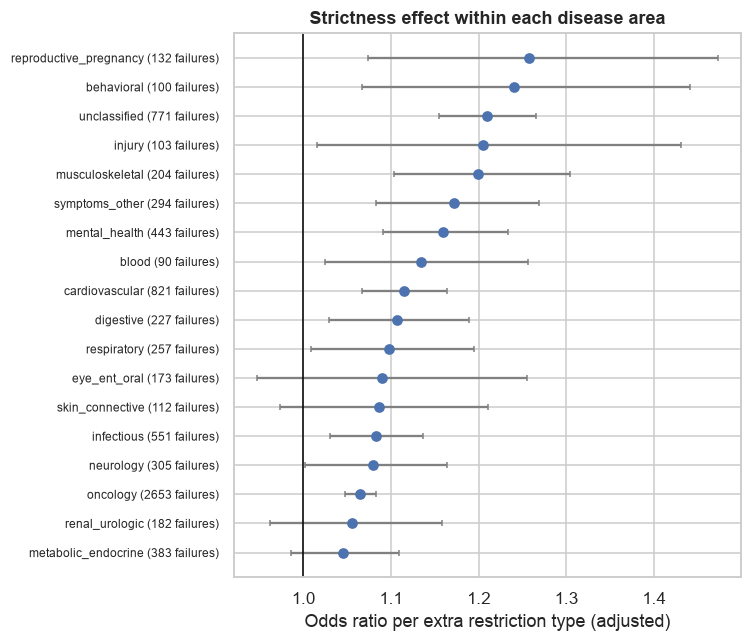

Heterogeneity test: chi2 = 70.8, df = 20, p = 1.4e-07
Areas with OR > 1 and CI excluding 1: 14 of 18


,area,n,failures,OR,lo,hi
8,metabolic_endocrine,14717,383,1.046,0.986,1.109
12,renal_urologic,3438,182,1.055,0.962,1.158
11,oncology,27098,2653,1.065,1.047,1.083
10,neurology,6350,305,1.080,1.002,1.164
5,infectious,13721,551,1.083,1.031,1.137
15,skin_connective,3082,112,1.086,0.973,1.211
4,eye_ent_oral,6635,173,1.090,0.947,1.255
14,respiratory,6092,257,1.098,1.009,1.194
3,digestive,3267,227,1.106,1.029,1.189
2,cardiovascular,14054,821,1.115,1.067,1.164


In [9]:
# Same data preparation as notebook 03, cell 7
m = labeled.copy()
m["phase"] = m["phase"].fillna("NA").astype(str)
m["lead_sponsor_class"] = m["lead_sponsor_class"].astype(str)
m["healthy_volunteers"] = m["healthy_volunteers"].astype(str)
m = m[m["lead_sponsor_class"].isin(["INDUSTRY", "OTHER", "NIH", "OTHER_GOV", "NETWORK", "FED"])]
m["year_c"] = m["start_year"] - 2014
CONTROLS = "C(phase) + C(lead_sponsor_class) + C(healthy_volunteers) + year_c"

def odds_ratio(formula, term, data):
    # Fit a logistic regression and return the odds ratio and 95% CI for one term
    fit = smf.logit(formula, data=data).fit(disp=0, maxiter=200)
    ci = np.exp(fit.conf_int().loc[term])
    return pd.Series({"OR": np.exp(fit.params[term]), "lo": ci[0], "hi": ci[1]})

rows = []
for area, g in m.groupby("primary_area"):
    if g["label"].sum() < 50:
        continue
    res = odds_ratio(f"label ~ n_rule_types + {CONTROLS}", "n_rule_types", g)
    rows.append({"area": area, "n": len(g), "failures": int(g["label"].sum()), **res})
within = pd.DataFrame(rows).sort_values("OR")

fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(within))
ax.errorbar(within["OR"], y, xerr=[within["OR"] - within["lo"], within["hi"] - within["OR"]],
            fmt="o", color="#4C72B0", ecolor="gray", capsize=2)
ax.axvline(1, color="black", lw=1)
ax.set_yticks(y, [f"{a} ({k} failures)" for a, k in zip(within["area"], within["failures"])], fontsize=8)
ax.set_xlabel("Odds ratio per extra restriction type (adjusted)")
ax.set_title("Strictness effect within each disease area")
plt.tight_layout(); savefig("within_area_or"); plt.show()

# Heterogeneity: does adding strictness x area interaction terms improve the fit?
base_fit = smf.logit(f"label ~ n_rule_types + C(primary_area) + {CONTROLS}", data=m).fit(disp=0, maxiter=200)
int_fit = smf.logit(f"label ~ n_rule_types * C(primary_area) + {CONTROLS}", data=m).fit(disp=0, maxiter=200)
lr = 2 * (int_fit.llf - base_fit.llf)
dof = int(int_fit.df_model - base_fit.df_model)
print(f"Heterogeneity test: chi2 = {lr:.1f}, df = {dof}, p = {stats.chi2.sf(lr, dof):.2g}")
print(f"Areas with OR > 1 and CI excluding 1: {(within['lo'] > 1).sum()} of {len(within)}")
within.round(3)

## 9. Notebook 03's regression, now with disease area

The same model as 03, with disease area added in two ways:
- **+ primary area**: one category per trial (from Step 5).
- **+ all area flags**: every True/False flag, so a cancer-plus-neuropathy trial is adjusted for both. This does
  not depend on the priority order, so it doubles as a check on that choice.

If disease area were the real explanation, the OR would fall toward 1.00.

In [10]:
flag_terms = " + ".join(f"area_{a}" for a in PRIORITY)
m = m.merge(flags.add_prefix("area_").astype(int), left_on="nct_id", right_index=True)

models = {
    "crude (strictness only)":       "label ~ n_rule_types",
    "adjusted (notebook 03)":        f"label ~ n_rule_types + {CONTROLS}",
    "+ primary disease area":        f"label ~ n_rule_types + {CONTROLS} + C(primary_area)",
    "+ all disease-area flags":      f"label ~ n_rule_types + {CONTROLS} + {flag_terms}",
}
ors = pd.DataFrame({name: odds_ratio(f, "n_rule_types", m) for name, f in models.items()}).T
ors["% of excess odds kept"] = (ors["OR"] - 1) / (ors.loc["adjusted (notebook 03)", "OR"] - 1) * 100
print("Odds ratio per additional restriction type (OR > 1 = higher failure odds)")
ors.round(3)

Odds ratio per additional restriction type (OR > 1 = higher failure odds)


,OR,lo,hi,% of excess odds kept
crude (strictness only),1.177,1.167,1.187,126.884
adjusted (notebook 03),1.140,1.127,1.152,100.000
+ primary disease area,1.097,1.084,1.110,69.357
+ all disease-area flags,1.097,1.084,1.110,69.586


## 10. Which restriction types were really disease-area effects?

Notebook 03 suspected that the "cancer-style" rules looked risky only because they show up in cancer trials. For
each rule type, the model is fitted twice: once with 03's controls, and once with primary disease area added. A rule
whose OR **drops toward 1** after adding area was mostly standing in for the disease. A rule whose OR **holds** has
an effect of its own. (Each rule is fitted on its own, as in 03, not all rules together.)

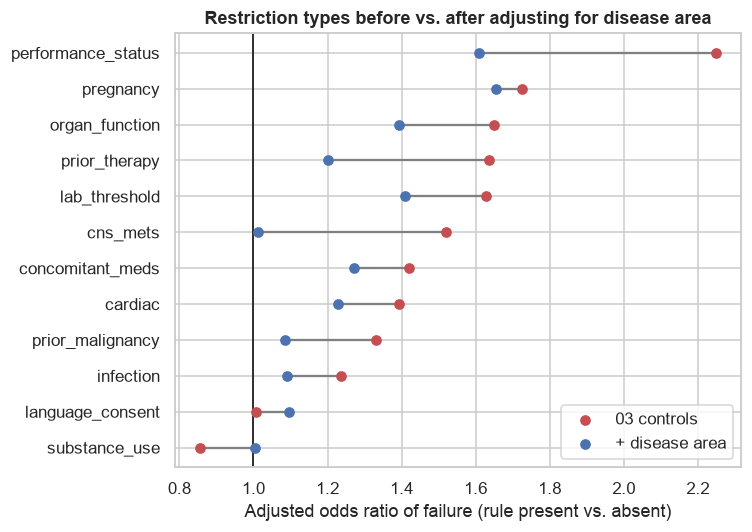

,rule,OR_before_area,OR_after_area,lo_after,hi_after
11,substance_use,0.86,1.00,0.94,1.07
9,language_consent,1.01,1.10,1.03,1.17
6,infection,1.24,1.09,1.02,1.16
2,prior_malignancy,1.33,1.09,1.00,1.18
7,cardiac,1.39,1.23,1.16,1.30
10,concomitant_meds,1.42,1.27,1.20,1.35
8,cns_mets,1.52,1.01,0.92,1.11
1,lab_threshold,1.63,1.41,1.33,1.50
3,prior_therapy,1.64,1.20,1.12,1.29
0,organ_function,1.65,1.39,1.31,1.48


In [11]:
rule_cols = [c for c in elig.columns if c.startswith("rule_")]
m[rule_cols] = m[rule_cols].astype(int)
rows = []
for col in rule_cols:
    before = odds_ratio(f"label ~ {col} + {CONTROLS}", col, m)
    after = odds_ratio(f"label ~ {col} + {CONTROLS} + C(primary_area)", col, m)
    rows.append({"rule": col.replace("rule_", ""), "OR_before_area": before["OR"], "OR_after_area": after["OR"],
                 "lo_after": after["lo"], "hi_after": after["hi"]})
rule_adj = pd.DataFrame(rows).sort_values("OR_before_area")

fig, ax = plt.subplots(figsize=(7, 5))
y = np.arange(len(rule_adj))
ax.hlines(y, rule_adj["OR_before_area"], rule_adj["OR_after_area"], color="gray", lw=1.5)
ax.scatter(rule_adj["OR_before_area"], y, color="#C44E52", label="03 controls", zorder=3)
ax.scatter(rule_adj["OR_after_area"], y, color="#4C72B0", label="+ disease area", zorder=3)
ax.axvline(1, color="black", lw=1)
ax.set_yticks(y, rule_adj["rule"])
ax.set_xlabel("Adjusted odds ratio of failure (rule present vs. absent)")
ax.set_title("Restriction types before vs. after adjusting for disease area")
ax.legend(loc="lower right")
plt.tight_layout(); savefig("rules_before_after"); plt.show()
rule_adj.round(2)

## 11. Save features

Saved for **all trials** (not just labeled ones): the survival models (10) also use trials stopped for other
reasons, and the representation work (06/08) needs completed U.S. trials regardless of label.

| Column | Meaning |
|---|---|
| `area_<name>` | True if the trial falls in that area (more than one can be True). Use these as model features. |
| `primary_area` | The single area chosen by the priority order. Use it for stratified analysis. |
| `n_areas` | Number of disease areas (MeSH-based) the trial spans |
| `area_source` | `mesh`, `keyword` (free-text fallback), `healthy`, or `none` |

In [12]:
out = flags.add_prefix("area_").join(primary).join(n_areas).join(source.rename("area_source"))
out = out.rename_axis("nct_id").reset_index()
out.to_parquet(ROOT / "data/processed/disease_area.parquet", index=False)
print(f"Saved {len(out):,} rows x {out.shape[1]} columns to data/processed/disease_area.parquet")

Saved 231,776 rows x 24 columns to data/processed/disease_area.parquet


## 12. Summary of findings

**Mapping**
- 79% of trials get a disease area from MeSH. The keyword fallback adds 10,674 more trials (4.6%) and labels
  7,373 healthy-volunteer studies (3.2%). 30,735 trials (13%) stay `unclassified`.
- 64% of MeSH-mapped trials span two or more areas, so the per-area flags (not one label per trial) are the right
  model features.

**Failure varies a lot by disease area**
- Failure ranges from 0.4% (healthy-volunteer studies), 1.9% (behavioral), and 2.6% (metabolic/endocrine, eye/ENT/oral)
  up to **9.8% for oncology**, twice the overall rate. Oncology is 16% of labeled trials but 34% of all enrollment
  failures.

**Is disease area a confounder? Mostly through oncology**
- Oncology is the outlier on **both** axes: mean strictness 4.1 restriction types, versus 0.9–2.9 in every other area.
  Across the other areas there is little link between how strict an area is and how often it fails
  (Spearman 0.22, p = 0.33).

**Strictness still matters within disease areas**
- Within every one of the 18 areas with enough failures, the adjusted OR per extra restriction type is above 1,
  and in 14 of them the 95% CI excludes 1.
- Even **within oncology alone**, failure rises from 4.7% at score 0 to 12.3% at 6+ (adjusted OR 1.07).
- The size of the effect differs between areas (heterogeneity p ≈ 1e-7). It is weakest in metabolic/endocrine
  (1.05), renal (1.06), and oncology (1.07), and strongest in reproductive/pregnancy (1.26), behavioral (1.24),
  musculoskeletal and injury (1.20).

**Notebook 03's model with disease area added**
- The adjusted OR falls from **1.14 to 1.10** (95% CI 1.08–1.11). About 30% of 03's strictness effect was disease
  area, and about 70% remains.
- The result is the same whether area enters as one primary category or as all flags, so the priority order in
  Step 5 does not drive it.

**Which restriction types were really disease-area effects**
- **Brain metastases** was entirely a cancer effect (OR 1.52 → 1.01). **Prior malignancy** (1.33 → 1.09),
  **prior therapy** (1.64 → 1.20), and **performance status** (2.25 → 1.61) were largely, but not fully, explained
  by disease area.
- **Pregnancy** (1.72 → 1.66), **lab thresholds** (1.63 → 1.41), and **organ function** (1.65 → 1.39) keep most of
  their effect. These are the rules most likely to restrict enrollment on their own.
- The apparent protective effect of **substance-use** exclusions (0.86) disappears (1.00). It came from behavioral
  and mental-health trials, which rarely fail.

**Caveats**
- Areas are broad. Inside oncology, tumor type, line of therapy, and biomarker selection probably matter, and a
  finer split (for example by MeSH tumor site) may explain more.
- `unclassified` (13%) mixes procedures, anesthesia, and PK studies, and the keyword fallback is rough.
- These are associations, not causal effects, and the strictness score is still the keyword v0 from 03.

**Next steps**
1. 09 (full model): merge `disease_area.parquet` and use the `area_*` flags and `n_areas` as features. Use
   `primary_area` to break SHAP results down by area.
2. 05 (baseline): disease area belongs in the **design-only baseline**. Otherwise the eligibility features get
   credit for disease-area differences, and their added value (the PR-AUC gain) is overstated.
4. Optional: split oncology by tumor site, or solid vs. blood cancers, and recheck.